In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('/kaggle/input/datasets/openfoodfacts/world-food-facts/en.openfoodfacts.org.products.tsv', 
                  sep='\t', low_memory=False, nrows=50000)  # sample for speed

# Keep relevant columns
cols = ['product_name', 'ingredients_text', 'allergens', 
        'energy_100g', 'fat_100g', 'carbohydrates_100g', 
        'sugars_100g', 'proteins_100g', 'salt_100g']
df = df[cols].dropna(subset=['allergens', 'ingredients_text'])

# Binary label: does this product contain milk (as an example allergen)?
df['has_milk'] = df['allergens'].str.contains('milk', case=False, na=False).astype(int)

# Features: nutrient columns (numeric, already project-relevant)
X = df[['energy_100g', 'fat_100g', 'carbohydrates_100g', 
        'sugars_100g', 'proteins_100g', 'salt_100g']].fillna(0).values
y = df['has_milk'].values

print(f"Dataset size: {X.shape}, Positive class: {y.sum()}/{len(y)}")

Dataset size: (317, 6), Positive class: 110/317


In [2]:
def init_mlp(input_dim, hidden_dim=16, output_dim=1, seed=42):
    rng = np.random.default_rng(seed)
    return {
        'W1': rng.normal(0, 0.1, (input_dim, hidden_dim)),
        'b1': np.zeros(hidden_dim),
        'W2': rng.normal(0, 0.1, (hidden_dim, output_dim)),
        'b2': np.zeros(output_dim)
    }

def forward(params, X):
    z1 = X @ params['W1'] + params['b1']
    a1 = np.maximum(0, z1)  # ReLU
    z2 = a1 @ params['W2'] + params['b2']
    a2 = 1 / (1 + np.exp(-z2))  # sigmoid
    return a1, a2

def bce_loss(y_true, y_pred):
    eps = 1e-8
    return -np.mean(y_true * np.log(y_pred + eps) + (1 - y_true) * np.log(1 - y_pred + eps))

def backward(params, X, y_true, a1, a2):
    m = X.shape[0]
    dz2 = (a2 - y_true.reshape(-1, 1)) / m
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0)
    da1 = dz2 @ params['W2'].T
    dz1 = da1 * (a1 > 0)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0)
    return {'W1': dW1, 'b1': db1, 'W2': dW2, 'b2': db2}

In [3]:
def sgd_update(params, grads, lr=0.01):
    for k in params:
        params[k] -= lr * grads[k]
    return params

def adam_update(params, grads, state, lr=0.001, b1=0.9, b2=0.999, eps=1e-8, t=1):
    for k in params:
        state['m'][k] = b1 * state['m'][k] + (1 - b1) * grads[k]
        state['v'][k] = b2 * state['v'][k] + (1 - b2) * (grads[k] ** 2)
        m_hat = state['m'][k] / (1 - b1 ** t)
        v_hat = state['v'][k] / (1 - b2 ** t)
        params[k] -= lr * m_hat / (np.sqrt(v_hat) + eps)
    return params, state

def rmsprop_update(params, grads, state, lr=0.001, decay=0.9, eps=1e-8):
    for k in params:
        state['s'][k] = decay * state['s'][k] + (1 - decay) * (grads[k] ** 2)
        params[k] -= lr * grads[k] / (np.sqrt(state['s'][k]) + eps)
    return params, state

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

def train(optimizer_name, epochs=200):
    params = init_mlp(X_train.shape[1])
    state = {'m': {k: np.zeros_like(v) for k, v in params.items()},
              'v': {k: np.zeros_like(v) for k, v in params.items()},
              's': {k: np.zeros_like(v) for k, v in params.items()}}
    losses, val_accs = [], []
    for t in range(1, epochs + 1):
        a1, a2 = forward(params, X_train)
        loss = bce_loss(y_train, a2)
        grads = backward(params, X_train, y_train, a1, a2)
        if optimizer_name == 'sgd':
            params = sgd_update(params, grads)
        elif optimizer_name == 'adam':
            params, state = adam_update(params, grads, state, t=t)
        elif optimizer_name == 'rmsprop':
            params, state = rmsprop_update(params, grads, state)
        losses.append(loss)
        _, val_pred = forward(params, X_val)
        val_accs.append(((val_pred > 0.5).flatten() == y_val).mean())
    return losses, val_accs, params  # now also returns final params

results = {name: train(name) for name in ['sgd', 'adam', 'rmsprop']}

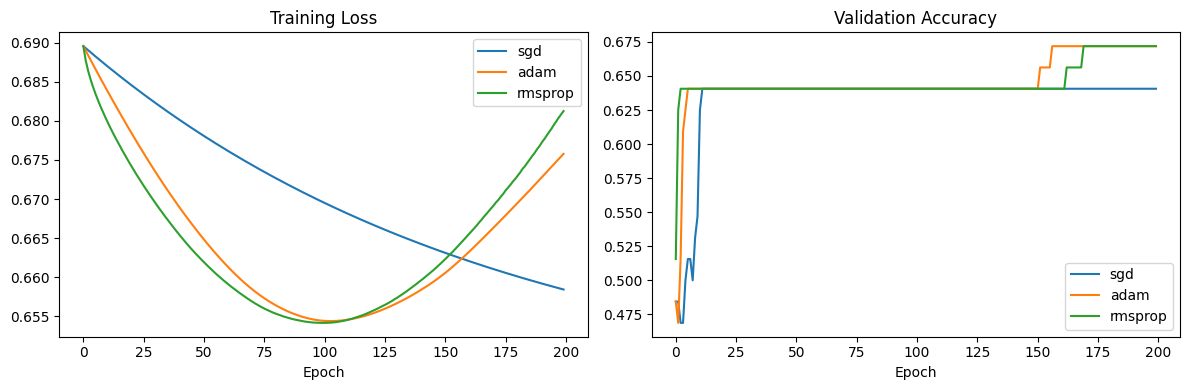

sgd: final loss=0.6584, final val_acc=0.6406
adam: final loss=0.6758, final val_acc=0.6719
rmsprop: final loss=0.6813, final val_acc=0.6719


In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, (losses, accs, params) in results.items():
    axes[0].plot(losses, label=name)
    axes[1].plot(accs, label=name)
axes[0].set_title('Training Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].set_title('Validation Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout()
plt.savefig('mlp_optimizer_comparison.png', dpi=150)
plt.show()

for name, (losses, accs, params) in results.items():
    print(f"{name}: final loss={losses[-1]:.4f}, final val_acc={accs[-1]:.4f}")

In [6]:
print(y_train.mean(), y_val.mean())  # what fraction is "has_milk"

0.3438735177865613 0.359375


In [7]:
from sklearn.metrics import precision_score, recall_score, f1_score

for name, (losses, accs, params) in results.items():
    _, val_pred = forward(params, X_val)
    pred_labels = (val_pred > 0.5).flatten()
    print(f"{name}: acc={accs[-1]:.4f}, F1={f1_score(y_val, pred_labels):.4f}, "
          f"Precision={precision_score(y_val, pred_labels):.4f}, "
          f"Recall={recall_score(y_val, pred_labels):.4f}")

sgd: acc=0.6406, F1=0.0000, Precision=0.0000, Recall=0.0000
adam: acc=0.6719, F1=0.1600, Precision=1.0000, Recall=0.0870
rmsprop: acc=0.6719, F1=0.1600, Precision=1.0000, Recall=0.0870


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [8]:
!ls -la /kaggle/input/datasets/openfoodfacts/world-food-facts

total 986584
drwxr-xr-x 2 nobody nogroup          0 Oct  6 09:40 .
drwxr-xr-x 3 root   root          4096 Oct  6 09:40 ..
-rw-r--r-- 1 nobody nogroup 1010256825 Oct  6 09:40 en.openfoodfacts.org.products.tsv


VAE on Real Nutrient Data

In [9]:
from pathlib import Path

INPUT_DIM = 8      # matches your 8 signature_cols from Step 2.1
HIDDEN_DIM = 6
LATENT_DIM = 2
WEIGHTS_PATH = Path('/kaggle/working/vae_weights.npz')  # dummy path, we won't actually load from it
class CravingVAE:
    def __init__(self, seed: int = 42):
        rng = np.random.default_rng(seed)

        def init(shape):
            return rng.normal(0, 0.3, size=shape).astype(np.float32)

        # Encoder: input -> hidden -> (mu, logvar)
        self.W1 = init((INPUT_DIM, HIDDEN_DIM))
        self.b1 = np.zeros(HIDDEN_DIM, dtype=np.float32)
        self.W_mu = init((HIDDEN_DIM, LATENT_DIM))
        self.b_mu = np.zeros(LATENT_DIM, dtype=np.float32)
        self.W_logvar = init((HIDDEN_DIM, LATENT_DIM))
        self.b_logvar = np.zeros(LATENT_DIM, dtype=np.float32)

        # Decoder: latent -> hidden -> reconstruction
        self.W2 = init((LATENT_DIM, HIDDEN_DIM))
        self.b2 = np.zeros(HIDDEN_DIM, dtype=np.float32)
        self.W3 = init((HIDDEN_DIM, INPUT_DIM))
        self.b3 = np.zeros(INPUT_DIM, dtype=np.float32)

    @staticmethod
    def _sigmoid(x):
        return 1.0 / (1.0 + np.exp(-x))

    def encode(self, x: np.ndarray):
        h = np.tanh(x @ self.W1 + self.b1)
        mu = h @ self.W_mu + self.b_mu
        logvar = h @ self.W_logvar + self.b_logvar
        return h, mu, logvar

    def decode(self, z: np.ndarray):
        h2 = np.tanh(z @ self.W2 + self.b2)
        recon = self._sigmoid(h2 @ self.W3 + self.b3)
        return h2, recon

    def embed(self, x: np.ndarray) -> np.ndarray:
        """Deterministic embedding for inference: just the mean, no sampling noise."""
        _, mu, _ = self.encode(x)
        return mu

    def train(self, data: np.ndarray, epochs: int = 4000, lr: float = 0.05, beta: float = 0.1, seed: int = 0):
        rng = np.random.default_rng(seed)
        n = data.shape[0]

        recon_history = []
        kl_history = []

        for epoch in range(epochs):
            h, mu, logvar = self.encode(data)
            std = np.exp(0.5 * logvar)
            eps = rng.normal(size=std.shape).astype(np.float32)
            z = mu + eps * std

            h2, recon = self.decode(z)

            # Reconstruction loss: binary cross-entropy (inputs are in [0,1])
            eps_num = 1e-7
            recon_c = np.clip(recon, eps_num, 1 - eps_num)
            bce = -(data * np.log(recon_c) + (1 - data) * np.log(1 - recon_c))
            recon_loss = bce.sum() / n

            # KL divergence to N(0, I)
            kl = -0.5 * np.sum(1 + logvar - mu**2 - np.exp(logvar)) / n

            recon_history.append(recon_loss)
            kl_history.append(kl)

            # ---- backward pass ----
            d_recon = (recon_c - data) / n
            dW3 = h2.T @ d_recon
            db3 = d_recon.sum(axis=0)
            dh2 = d_recon @ self.W3.T
            dh2_pre = dh2 * (1 - h2**2)
            dW2 = z.T @ dh2_pre
            db2 = dh2_pre.sum(axis=0)
            dz = dh2_pre @ self.W2.T

            dmu_kl = mu / n
            dlogvar_kl = 0.5 * (np.exp(logvar) - 1) / n

            dmu = dz + beta * dmu_kl
            dlogvar = dz * eps * 0.5 * std + beta * dlogvar_kl

            dW_mu = h.T @ dmu
            db_mu = dmu.sum(axis=0)
            dW_logvar = h.T @ dlogvar
            db_logvar = dlogvar.sum(axis=0)

            dh = dmu @ self.W_mu.T + dlogvar @ self.W_logvar.T
            dh_pre = dh * (1 - h**2)
            dW1 = data.T @ dh_pre
            db1 = dh_pre.sum(axis=0)

            for param, grad in [
                (self.W1, dW1), (self.b1, db1),
                (self.W_mu, dW_mu), (self.b_mu, db_mu),
                (self.W_logvar, dW_logvar), (self.b_logvar, db_logvar),
                (self.W2, dW2), (self.b2, db2),
                (self.W3, dW3), (self.b3, db3),
            ]:
                param -= lr * grad

        return recon_history, kl_history

    def save(self, path: Path = WEIGHTS_PATH):
        np.savez(
            path,
            W1=self.W1, b1=self.b1, W_mu=self.W_mu, b_mu=self.b_mu,
            W_logvar=self.W_logvar, b_logvar=self.b_logvar,
            W2=self.W2, b2=self.b2, W3=self.W3, b3=self.b3,
        )

    def load(self, path: Path = WEIGHTS_PATH):
        d = np.load(path)
        self.W1, self.b1 = d["W1"], d["b1"]
        self.W_mu, self.b_mu = d["W_mu"], d["b_mu"]
        self.W_logvar, self.b_logvar = d["W_logvar"], d["b_logvar"]
        self.W2, self.b2 = d["W2"], d["b2"]
        self.W3, self.b3 = d["W3"], d["b3"]



In [10]:
# Fresh load, larger nrows, no dependency on the MLP's filtered df
df_vae_raw = pd.read_csv(
    '/kaggle/input/datasets/openfoodfacts/world-food-facts/en.openfoodfacts.org.products.tsv',
    sep='\t', low_memory=False, nrows=100000,
    usecols=['product_name', 'sugars_100g', 'salt_100g', 'fat_100g',
             'proteins_100g', 'carbohydrates_100g', 'energy_100g']
)

nutrient_cols = ['sugars_100g', 'salt_100g', 'fat_100g',
                  'proteins_100g', 'carbohydrates_100g', 'energy_100g']

for col in nutrient_cols:
    df_vae_raw[col] = pd.to_numeric(df_vae_raw[col], errors='coerce')
    df_vae_raw[col] = df_vae_raw[col].fillna(df_vae_raw[col].median())

df2 = df_vae_raw.copy()

def normalize(col):
    return (col - col.min()) / (col.max() - col.min() + 1e-8)

df2['sweet']   = normalize(df2['sugars_100g'])
df2['salty']   = normalize(df2['salt_100g'])
df2['creamy']  = normalize(df2['fat_100g'])
df2['savory']  = normalize(df2['proteins_100g'])
df2['fruity']  = normalize(df2['sugars_100g'] - df2['fat_100g']).clip(0, 1)
df2['dense']   = normalize(df2['energy_100g'])
df2['carby']   = normalize(df2['carbohydrates_100g'])
df2['light']   = 1 - df2['dense']

signature_cols = ['sweet', 'salty', 'creamy', 'savory', 'fruity', 'dense', 'carby', 'light']
X_vae = df2[signature_cols].fillna(0).values

print(f"df2 shape: {df2.shape}")
print(f"X_vae shape: {X_vae.shape}")

df2 shape: (100000, 15)
X_vae shape: (100000, 8)


In [11]:
np.random.seed(42)
if len(X_vae) > 20000:
    idx = np.random.choice(len(X_vae), 20000, replace=False)
    X_vae = X_vae[idx]
    df2 = df2.iloc[idx].reset_index(drop=True)

print(f"Final VAE dataset: {X_vae.shape}")

Final VAE dataset: (20000, 8)


In [12]:
vae = CravingVAE(seed=42)
X_vae_f32 = X_vae.astype(np.float32)
recon_history, kl_history = vae.train(X_vae_f32, epochs=4000, lr=0.05, beta=0.1)

print(f"Final reconstruction loss: {recon_history[-1]:.4f}")
print(f"Final KL divergence: {kl_history[-1]:.4f}")

Final reconstruction loss: 2.6158
Final KL divergence: 0.7027


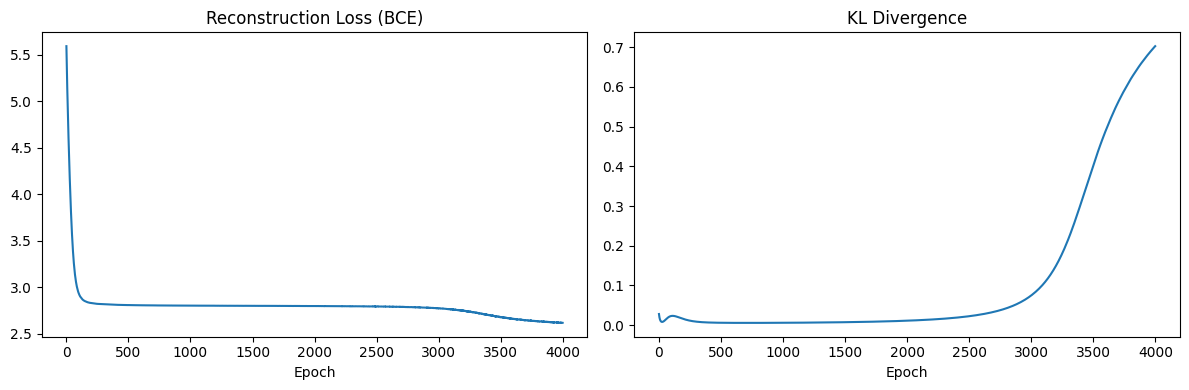

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(recon_history)
axes[0].set_title('Reconstruction Loss (BCE)'); axes[0].set_xlabel('Epoch')
axes[1].plot(kl_history)
axes[1].set_title('KL Divergence'); axes[1].set_xlabel('Epoch')
plt.tight_layout()
plt.savefig('vae_training_curves.png', dpi=150)
plt.show()

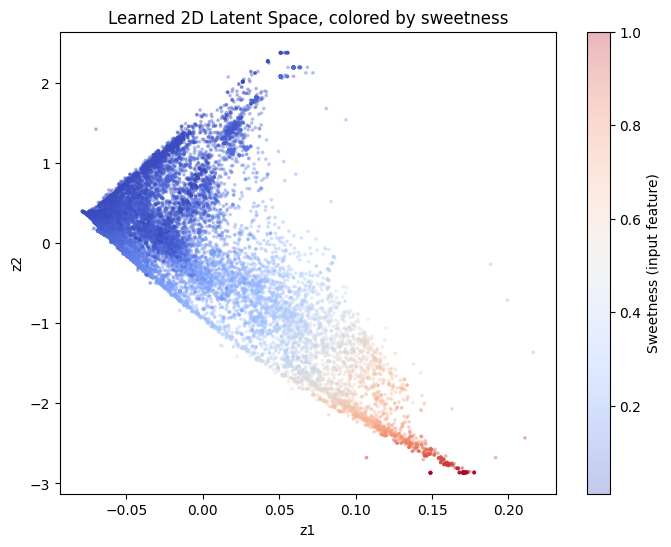

In [14]:
embeddings = vae.embed(X_vae_f32)

plt.figure(figsize=(8, 6))
plt.scatter(embeddings[:, 0], embeddings[:, 1], s=3, alpha=0.3, c=df2['sweet'], cmap='coolwarm')
plt.colorbar(label='Sweetness (input feature)')
plt.title('Learned 2D Latent Space, colored by sweetness')
plt.xlabel('z1'); plt.ylabel('z2')
plt.savefig('vae_latent_space.png', dpi=150)
plt.show()

In [15]:
# Simulate scan sequences: each user has a sequence of scans, 
# label = will they scan a flagged item next (1) or not (0)
np.random.seed(42)
n_users = 2000
seq_len = 10
n_features = 3  # e.g. [verdict_code, hour_of_day, days_since_last_scan]

X_seq = np.random.rand(n_users, seq_len, n_features)
# inject a pattern: if last 3 scans trend toward "flagged" (feature 0 rising), next scan likely flagged too
trend = X_seq[:, -3:, 0].mean(axis=1)
y_seq = (trend > 0.6).astype(int)

print(f"Synthetic dataset: {X_seq.shape}, positive rate: {y_seq.mean():.2f}")

Synthetic dataset: (2000, 10, 3), positive rate: 0.28


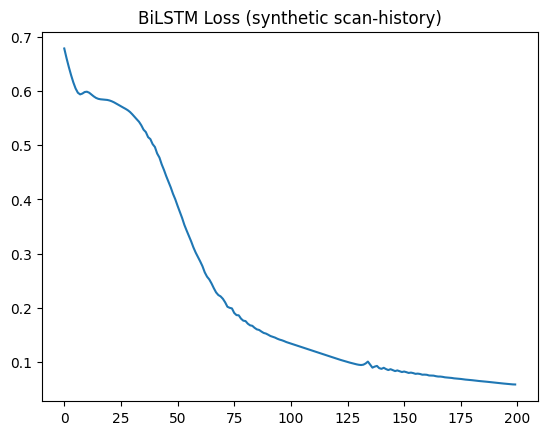

Final loss: 0.0590, Final train acc: 0.9880


In [16]:
import torch, torch.nn as nn

class BiLSTMNudge(nn.Module):
    def __init__(self, input_dim=3, hidden=16):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden*2, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return torch.sigmoid(self.fc(out[:, -1, :]))

model = BiLSTMNudge()
X_t = torch.tensor(X_seq, dtype=torch.float32)
y_t = torch.tensor(y_seq, dtype=torch.float32).unsqueeze(1)

opt = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.BCELoss()
losses = []
for epoch in range(200):
    opt.zero_grad()
    pred = model(X_t)
    loss = loss_fn(pred, y_t)
    loss.backward()
    opt.step()
    losses.append(loss.item())

import matplotlib.pyplot as plt
plt.plot(losses); plt.title('BiLSTM Loss (synthetic scan-history)')
plt.savefig('bilstm_loss.png', dpi=150); plt.show()
print(f"Final loss: {losses[-1]:.4f}, Final train acc: {((pred>0.5).float()==y_t).float().mean():.4f}")

In [17]:
# Split before training (add this before the training loop, then retrain)
from sklearn.model_selection import train_test_split
X_tr, X_val, y_tr, y_val = train_test_split(X_seq, y_seq, test_size=0.2, random_state=42)
X_tr_t = torch.tensor(X_tr, dtype=torch.float32)
y_tr_t = torch.tensor(y_tr, dtype=torch.float32).unsqueeze(1)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)

# retrain on X_tr_t/y_tr_t, then:
model.eval()
with torch.no_grad():
    val_pred = model(X_val_t)
    val_acc = ((val_pred > 0.5).float() == y_val_t).float().mean()
print(f"Validation accuracy: {val_acc:.4f}")

Validation accuracy: 0.9900


In [18]:
import numpy as np

np.random.seed(42)
n_users = 2000
seq_len = 10
n_features = 3  # [verdict_code, hour_of_day, days_since_last_scan]

X_seq = np.random.rand(n_users, seq_len, n_features)
trend = X_seq[:, -3:, 0].mean(axis=1)
y_seq = (trend > 0.6).astype(int)

print(f"Synthetic dataset: {X_seq.shape}, positive rate: {y_seq.mean():.2f}")

Synthetic dataset: (2000, 10, 3), positive rate: 0.28


In [19]:
import torch, torch.nn as nn

class BiLSTMNudge(nn.Module):
    def __init__(self, input_dim=3, hidden=16):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden*2, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return torch.sigmoid(self.fc(out[:, -1, :]))

model = BiLSTMNudge()
X_t = torch.tensor(X_seq, dtype=torch.float32)
y_t = torch.tensor(y_seq, dtype=torch.float32).unsqueeze(1)

opt = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.BCELoss()
losses = []
for epoch in range(200):
    opt.zero_grad()
    pred = model(X_t)
    loss = loss_fn(pred, y_t)
    loss.backward()
    opt.step()
    losses.append(loss.item())

final_acc = ((pred > 0.5).float() == y_t).float().mean().item()
print(f"Final loss: {losses[-1]:.4f}, Final train acc: {final_acc:.4f}")

Final loss: 0.0499, Final train acc: 0.9905


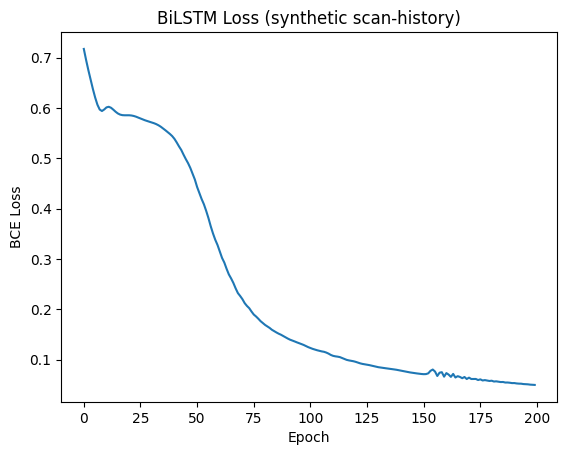

In [20]:
import matplotlib.pyplot as plt
plt.plot(losses)
plt.title('BiLSTM Loss (synthetic scan-history)')
plt.xlabel('Epoch'); plt.ylabel('BCE Loss')
plt.savefig('bilstm_loss.png', dpi=150)
plt.show()

In [21]:
torch.save(model.state_dict(), 'bilstm_nudge.pt')